# 04 - Node-level Evaluation, Final Test and Explainability
**Project:** Predictive Maintenance of IoT Sensors (Intel Berkeley Research Lab)
**CRISP-DM phase:** 5 - Evaluation

## 0. Setup and definitions

In [2]:
import sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.metrics import average_precision_score, roc_auc_score

try:                                    # Google Colab
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT = Path("/content/drive/MyDrive/sensor-failure-prediction")
except ImportError:
    PROJECT = Path("..").resolve()

PROC_DIR  = PROJECT / "data/processed"
MODEL_DIR = PROJECT / "models"
RES_DIR   = PROJECT / "reports/results"; RES_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR   = PROJECT / "reports/figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)

# ---- switches and design parameters ----
RUN_TEST     = True          # the ONE-TIME switch for the locked test nodes (Part B)
MIN_LEAD_H   = 6              # an alert must come at least this many hours before the failure to be useful
MAX_LEAD_H   = 168            # an alert more than 7 days before the failure counts as a false alarm (too early to be believed)
FA_BUDGET    = 0.02           # false alarms per node-day (about 1 per day for a fleet of 50 nodes)
EP_GAP_H     = 12             # alert minutes less than 12 h apart are one alert episode
SMOOTH_BINS  = [1, 3, 6, 18]  # smoothing windows in 10-minute bins (1 = none, 18 = 3 hours)
SEED = 42
sns.set_theme(style="whitegrid"); plt.rcParams["figure.dpi"] = 110
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

bundle = joblib.load(MODEL_DIR / "best_model_intel.joblib")
model, FEATS, H, NAME = bundle["model"], bundle["features"], bundle["horizon_h"], bundle["name"]
nodes_split = json.load(open(PROC_DIR / "split_nodes.json"))
DEV_NODES, TEST_NODES = nodes_split["dev_nodes"], nodes_split["test_nodes"]
onsets = pd.read_csv(PROC_DIR / "mote_onsets.csv", index_col="moteid", parse_dates=["first_ts", "last_ts", "t_onset", "t_lowv"])
ONSET = onsets.t_onset.to_dict()
oof = pd.read_parquet(RES_DIR / "intel_oof_predictions.parquet")
print(f"Model: {NAME} | horizon of the model: {H} h | features: {len(FEATS)} | development nodes: {len(DEV_NODES)} | locked test nodes: {len(TEST_NODES)}")

Mounted at /content/drive
Model: LogisticRegression | horizon of the model: 24 h | features: 48 | development nodes: 41 | locked test nodes: 10


### Definitions (per node)
- **Alert minute:** (smoothed) score >= threshold. Smoothing = mean of the last few bins (the past only).
- **Useful alert:** an alert between `MAX_LEAD_H` and `MIN_LEAD_H` hours before the failure. **Lead time** = failure time minus the *first* useful alert.
- **Late:** the first alert comes in the last `MIN_LEAD_H` hours (too late to react). **Missed:** no alert.
- **False alarm:** an alert episode more than `MAX_LEAD_H` before the failure. **False alarms per node-day** = false episodes / days observed before that point.
- We tune the smoothing and the threshold to **maximise the share of nodes with a useful alert, within the false-alarm budget** `FA_BUDGET`.

**Correction after the first test look (kept visible on purpose).** The first definition ("v1") gave credit for any alert *minute* inside the window, even when the alert had started
**earlier** and simply stayed on (test node 8: an alert started more than 7 days before the failure and was still on at the window edge). The **strict** definition below
gives credit only when an alert **episode starts inside the window**; an episode that starts earlier is a false alarm. The model, the smoothing and the threshold are **unchanged**:
only the way we count is corrected, and both versions are reported.

In [3]:
def smooth_nodes(df, score, bins):
    """Per node: timestamps and causally smoothed scores."""
    out = {}
    for m, g in df.assign(_s=score).groupby("moteid"):
        g = g.sort_values("timestamp")
        s = pd.Series(g["_s"].values, index=pd.DatetimeIndex(g.timestamp))
        sm = s if bins <= 1 else s.rolling(f"{10 * bins}min", min_periods=1).mean()
        out[int(m)] = (sm.index.values, sm.values)
    return out

H1, GAP = np.timedelta64(1, "h"), np.timedelta64(EP_GAP_H, "h")

def eval_setting(nsm, thr):
    rows = []
    for m, (ts, sm) in nsm.items():
        al = ts[sm >= thr]
        onset = ONSET.get(m, pd.NaT)
        first = ts[0]
        if pd.notna(onset):
            on = np.datetime64(onset)
            lead_all = (on - al) / H1
            useful = lead_all[(lead_all >= MIN_LEAD_H) & (lead_all <= MAX_LEAD_H)]
            late = ((lead_all >= 0) & (lead_all < MIN_LEAD_H)).any()
            false_al = al[lead_all > MAX_LEAD_H]
            end_normal = min(on - np.timedelta64(MAX_LEAD_H, "h"), ts[-1])
            detected = len(useful) > 0
            lead = useful.max() if detected else np.nan
            outcome = "detected" if detected else ("late" if late else "missed")
        else:
            false_al, end_normal, lead, outcome = al, ts[-1], np.nan, "healthy"
        n_fa = 0 if len(false_al) == 0 else 1 + int((np.diff(false_al) > GAP).sum())
        days = max((end_normal - first) / np.timedelta64(1, "D"), 0.0)
        rows.append({"node": m, "outcome": outcome, "lead_h": lead, "false_alarms": n_fa, "normal_days": days})
    return pd.DataFrame(rows)

def summarize(res):
    f = res[res.outcome != "healthy"]
    return {"detected_%": 100 * (f.outcome == "detected").mean(), "late_%": 100 * (f.outcome == "late").mean(),
            "missed_%": 100 * (f.outcome == "missed").mean(), "median_lead_h": f.lead_h.median(),
            "false_alarms_per_node_day": res.false_alarms.sum() / max(res.normal_days.sum(), 1e-9)}

def tune(df, score, label):
    """Sweep smoothing and threshold on the development nodes; choose under the false-alarm budget."""
    rows = []
    for b in SMOOTH_BINS:
        nsm = smooth_nodes(df, score, b)
        allv = np.concatenate([v for _, v in nsm.values()])
        for t in np.unique(np.quantile(allv[~np.isnan(allv)], np.linspace(0.30, 0.9995, 120))):
            rows.append({"model": label, "smooth_bins": b, "threshold": t, **summarize(eval_setting(nsm, t))})
    sw = pd.DataFrame(rows)
    ok = sw[sw.false_alarms_per_node_day <= FA_BUDGET]
    best = (ok.sort_values(["detected_%", "median_lead_h", "threshold"], ascending=[False, False, False]).iloc[0]
            if len(ok) else sw.sort_values("false_alarms_per_node_day").iloc[0])
    return sw, best

# Part A - Development nodes (out-of-fold predictions)
Every score here was produced by a model that had **not seen the node** (leave-nodes-out cross-validation of notebook 03).
We compare the best model with the simple voltage rule, each tuned the same way.

In [4]:
dfo = oof[["timestamp", "moteid"]].copy()
cands = {NAME: oof[NAME].values, "rule: share of 24 h below 2.4 V": oof["rule: share of 24 h below 2.4 V"].values,
         "rule: low voltage (6 h mean)": oof["rule: low voltage (6 h mean)"].values}
sweeps, chosen = {}, {}
for label, sc in cands.items():
    sweeps[label], chosen[label] = tune(dfo, sc, label)
tab = pd.DataFrame(chosen).T[["smooth_bins", "threshold", "detected_%", "late_%", "missed_%", "median_lead_h", "false_alarms_per_node_day"]]
tab

,smooth_bins,threshold,detected_%,late_%,missed_%,median_lead_h,false_alarms_per_node_day
LogisticRegression,1,0.108,92.683,0.000,7.317,65.573,0.019
rule: share of 24 h below 2.4 V,1,0.022,95.122,0.000,4.878,95.538,0.007
rule: low voltage (6 h mean),18,-2.441,95.122,0.000,4.878,112.926,0.018


In [5]:
BEST = chosen[NAME]
SMOOTH, THR = int(BEST.smooth_bins), float(BEST.threshold)
print(f"Chosen for {NAME}: smoothing {SMOOTH} bins ({10*SMOOTH} min), threshold {THR:.4f}")

nsm = smooth_nodes(dfo, cands[NAME], SMOOTH)
res_dev = eval_setting(nsm, THR).merge(onsets[["fail_type"]], left_on="node", right_index=True)
display(res_dev.sort_values("lead_h").head(12))
print(res_dev.outcome.value_counts().to_string())

Chosen for LogisticRegression: smoothing 1 bins (10 min), threshold 0.1079


,node,outcome,lead_h,false_alarms,normal_days,fail_type
38,51,detected,23.487,0,14.062,garbage
12,18,detected,26.197,0,0.758,garbage
30,42,detected,27.507,0,14.216,garbage
13,19,detected,34.826,0,10.965,garbage
6,10,detected,36.087,0,14.587,garbage
36,49,detected,36.382,0,14.953,garbage
9,14,detected,37.600,0,15.025,garbage
15,21,detected,38.303,0,13.221,garbage
3,6,detected,40.451,0,11.269,garbage
40,54,detected,43.346,0,14.466,garbage


outcome
detected    38
missed       3


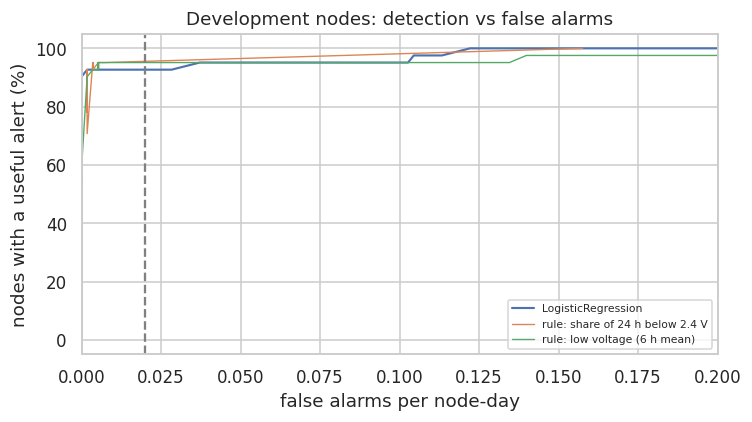

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
for label, sw in sweeps.items():
    g = sw[sw.smooth_bins == int(chosen[label].smooth_bins)].sort_values("false_alarms_per_node_day")
    ax.plot(g.false_alarms_per_node_day, g["detected_%"], label=label, lw=1.4 if label == NAME else 0.9)
ax.axvline(FA_BUDGET, color="gray", ls="--"); ax.set_xlim(0, 0.2)
ax.set_xlabel("false alarms per node-day"); ax.set_ylabel("nodes with a useful alert (%)")
ax.set_title("Development nodes: detection vs false alarms"); ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(FIG_DIR / "10_intel_detection_vs_fa.png", bbox_inches="tight"); plt.show()

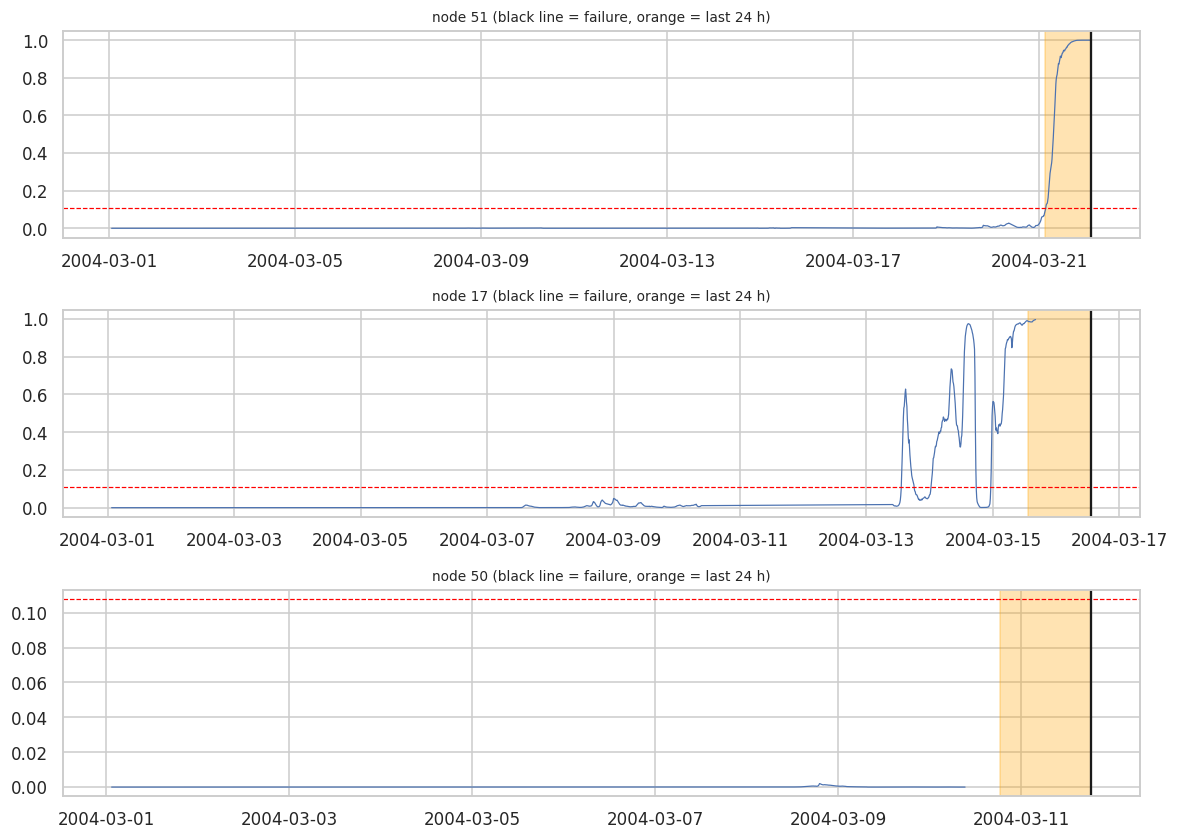

In [7]:
# Score of a few nodes with the chosen threshold
show = res_dev.sort_values("lead_h").node.iloc[[0, len(res_dev) // 2, -1]].tolist() if res_dev.lead_h.notna().sum() >= 3 else res_dev.node.head(3).tolist()
fig, axes = plt.subplots(len(show), 1, figsize=(11, 2.6 * len(show)), sharex=False)
for ax, m in zip(np.atleast_1d(axes), show):
    ts_, sm_ = nsm[int(m)]
    ax.plot(ts_, sm_, lw=0.8); ax.axhline(THR, color="red", ls="--", lw=0.8)
    if pd.notna(ONSET.get(int(m))):
        ax.axvline(ONSET[int(m)], color="k"); ax.axvspan(ONSET[int(m)] - pd.Timedelta(hours=H), ONSET[int(m)], color="orange", alpha=0.3)
    ax.set_title(f"node {int(m)} (black line = failure, orange = last {H} h)", fontsize=9)
plt.tight_layout(); plt.savefig(FIG_DIR / "11_intel_node_examples.png", bbox_inches="tight"); plt.show()

# Part B - Locked test nodes
**Before switching `RUN_TEST` to `True`:**
- Use it once, with the final model, smoothing and threshold from Part A, unchanged.
- Report the result whatever it is. A weak test result is a valid result. Tuning until the test looks good is not allowed.
- The test has only **10 nodes** (1 silent, 9 garbage). Say in the report that the numbers are noisy.

In [8]:
results = {"model": NAME, "horizon_h": H, "smooth_bins": SMOOTH, "threshold": THR, "fa_budget": FA_BUDGET,
           "development": {**summarize(res_dev), "n_nodes": int(len(res_dev))}}

if RUN_TEST:
    test = (pd.read_parquet(PROC_DIR / "features_intel.parquet", filters=[("moteid", "in", TEST_NODES)])
              .reset_index().sort_values(["moteid", "timestamp"]).reset_index(drop=True))
    s_test = model.predict_proba(test[FEATS])[:, 1]
    nsm_t = smooth_nodes(test[["timestamp", "moteid"]], s_test, SMOOTH)
    res_test = eval_setting(nsm_t, THR).merge(onsets[["fail_type"]], left_on="node", right_index=True)
    display(res_test)
    print({k: round(v, 3) for k, v in summarize(res_test).items()})

    # minute level, for the record
    y_t = (test.ttf_h <= H).astype(int).values
    results["test"] = {**summarize(res_test), "n_nodes": int(len(res_test)),
                       "pr_auc": float(average_precision_score(y_t, s_test)), "roc_auc": float(roc_auc_score(y_t, s_test)),
                       "base_rate": float(y_t.mean())}
    print("Minute level:", {k: round(v, 3) for k, v in results["test"].items() if k in ("pr_auc", "roc_auc", "base_rate")})
else:
    print("Test nodes are LOCKED (RUN_TEST = False).")

,node,outcome,lead_h,false_alarms,normal_days,fail_type
0,4,detected,59.695,0,13.230,garbage
1,8,detected,167.884,1,6.683,silent
2,12,detected,68.927,0,15.740,garbage
3,23,detected,159.920,0,14.136,garbage
4,24,detected,152.762,0,13.837,garbage
5,33,detected,42.379,0,14.946,garbage
6,37,detected,157.613,1,14.032,garbage
7,38,detected,128.018,0,11.959,garbage
8,44,detected,72.747,0,16.358,garbage
9,52,detected,53.963,0,15.186,garbage


{'detected_%': np.float64(100.0), 'late_%': np.float64(0.0), 'missed_%': np.float64(0.0), 'median_lead_h': 100.383, 'false_alarms_per_node_day': np.float64(0.015)}
Minute level: {'pr_auc': 0.686, 'roc_auc': 0.987, 'base_rate': 0.06}


In [9]:
# The simple rule on the same test nodes, tuned on the development nodes only (for comparison)
if RUN_TEST:
    rl = "rule: share of 24 h below 2.4 V"
    rb = chosen[rl]
    rule_test = (test.volt_low_share_24h.values)
    nsm_r = smooth_nodes(test[["timestamp", "moteid"]], rule_test, int(rb.smooth_bins))
    res_rule = eval_setting(nsm_r, float(rb.threshold))
    cmp_ = pd.DataFrame({NAME: summarize(res_test), rl: summarize(res_rule)}).T
    results["test_rule"] = summarize(res_rule)
    display(cmp_)

,detected_%,late_%,missed_%,median_lead_h,false_alarms_per_node_day
LogisticRegression,100.000,0.000,0.000,100.383,0.015
rule: share of 24 h below 2.4 V,90.000,0.000,10.000,72.113,0.000


# Strict evaluation, blind tails and a no-data alert
Added after the first test look. Same model, same smoothing, same threshold. Nothing is re-tuned.

- **Strict:** an alert **episode must start** between `MAX_LEAD_H` and `MIN_LEAD_H` before the failure. Episodes that start earlier are false alarms.
- **Blind tail:** hours between the last scored row of a node and its failure. During a blind tail the model sees nothing (the node reports too little for features to exist).
- **No-data alert (post-hoc):** an alert raised when a node has produced no scorable row for `NODATA_H` hours. Its parameter was chosen **after** seeing test node 8, so it is an
  exploratory add-on, **not** a test result of the original design.

In [10]:
NODATA_H = 6

def episodes(al):
    if len(al) == 0:
        e = np.array([], dtype="datetime64[ns]"); return e, e
    br = np.where(np.diff(al) > GAP)[0]
    return np.r_[al[0], al[br + 1]], np.r_[al[br], al[-1]]

def nodata_times(ts, hours, onset):
    d = np.timedelta64(int(hours * 60), "m")
    t = list(ts[np.where(np.diff(ts) >= d)[0]] + d)          # a gap: last scored row + hours
    if pd.notna(onset) and ts[-1] + d < np.datetime64(onset):  # silence until the failure
        t.append(ts[-1] + d)
    return np.array(t, dtype="datetime64[ns]")

def eval_alerts_strict(ts, al, onset):
    st, en = episodes(al)
    if pd.notna(onset):
        on = np.datetime64(onset)
        lead_st = (on - st) / H1
        useful = lead_st[(lead_st >= MIN_LEAD_H) & (lead_st <= MAX_LEAD_H)]
        late = ((lead_st >= 0) & (lead_st < MIN_LEAD_H)).any()
        n_fa = int((lead_st > MAX_LEAD_H).sum())
        early_on = bool(((lead_st > MAX_LEAD_H) & (en >= on - np.timedelta64(MAX_LEAD_H, "h"))).any())
        detected = len(useful) > 0
        lead = useful.max() if detected else np.nan
        outcome = "detected" if detected else ("late" if late else "missed")
        end_normal = min(on - np.timedelta64(MAX_LEAD_H, "h"), ts[-1])
        blind = (on - ts[-1]) / H1
    else:
        n_fa, early_on, lead, outcome, end_normal, blind = len(st), False, np.nan, "healthy", ts[-1], np.nan
    return {"outcome": outcome, "lead_h": lead, "false_alarms": n_fa, "early_alert_stayed_on": early_on,
            "normal_days": max((end_normal - ts[0]) / np.timedelta64(1, "D"), 0.0), "blind_tail_h": blind}

def eval_strict(nsm, thr, nodata_h=None):
    rows = []
    for m, (ts, sm) in nsm.items():
        al = ts[sm >= thr]
        onset = ONSET.get(m, pd.NaT)
        if nodata_h is not None:
            al = np.sort(np.concatenate([al, nodata_times(ts, nodata_h, onset)]))
        rows.append({"node": m, **eval_alerts_strict(ts, al, onset)})
    return pd.DataFrame(rows)

# ---- development nodes: model and rules, v1 against strict ----
rows, strict_dev = {}, {}
for label in cands:
    b_ = chosen[label]
    nsm_c = smooth_nodes(dfo, cands[label], int(b_.smooth_bins))
    strict_dev[label] = eval_strict(nsm_c, float(b_.threshold))
    rows[f"{label} (v1)"] = summarize(eval_setting(nsm_c, float(b_.threshold)))
    rows[f"{label} (strict)"] = summarize(strict_dev[label])
cmp_dev_strict = pd.DataFrame(rows).T
results["development_strict"] = summarize(strict_dev[NAME])
cmp_dev_strict

,detected_%,late_%,missed_%,median_lead_h,false_alarms_per_node_day
LogisticRegression (v1),92.683,0.000,7.317,65.573,0.019
LogisticRegression (strict),92.683,0.000,7.317,65.573,0.019
rule: share of 24 h below 2.4 V (v1),95.122,0.000,4.878,95.538,0.007
rule: share of 24 h below 2.4 V (strict),95.122,0.000,4.878,89.679,0.007
rule: low voltage (6 h mean) (v1),95.122,0.000,4.878,112.926,0.018
rule: low voltage (6 h mean) (strict),95.122,0.000,4.878,109.030,0.018


In [11]:
# ---- locked test nodes: v1 against strict (only when RUN_TEST) ----
if RUN_TEST:
    res_test_s = eval_strict(nsm_t, THR).merge(onsets[["fail_type"]], left_on="node", right_index=True)
    res_rule_s = eval_strict(nsm_r, float(rb.threshold))
    display(res_test_s)
    cmp_test = pd.DataFrame({f"{NAME} (v1)": summarize(res_test), f"{NAME} (strict)": summarize(res_test_s),
                             f"{rl} (v1)": summarize(res_rule), f"{rl} (strict)": summarize(res_rule_s)}).T
    display(cmp_test)
    results["test_strict"] = summarize(res_test_s); results["test_rule_strict"] = summarize(res_rule_s)
else:
    print("Test nodes are LOCKED (RUN_TEST = False).")

,node,outcome,lead_h,false_alarms,early_alert_stayed_on,normal_days,blind_tail_h,fail_type
0,4,detected,59.695,0,False,13.230,0.029,garbage
1,8,missed,NaN,1,True,6.683,105.717,silent
2,12,detected,68.927,0,False,15.740,8.093,garbage
3,23,detected,159.920,0,False,14.136,0.087,garbage
4,24,detected,152.762,0,False,13.837,0.095,garbage
5,33,detected,42.379,0,False,14.946,0.046,garbage
6,37,detected,157.613,1,False,14.032,0.113,garbage
7,38,detected,128.018,0,False,11.959,0.018,garbage
8,44,detected,72.747,0,False,16.358,0.081,garbage
9,52,detected,53.963,0,False,15.186,0.129,garbage


,detected_%,late_%,missed_%,median_lead_h,false_alarms_per_node_day
LogisticRegression (v1),100.000,0.000,0.000,100.383,0.015
LogisticRegression (strict),90.000,0.000,10.000,72.747,0.015
rule: share of 24 h below 2.4 V (v1),90.000,0.000,10.000,72.113,0.000
rule: share of 24 h below 2.4 V (strict),90.000,0.000,10.000,72.113,0.000


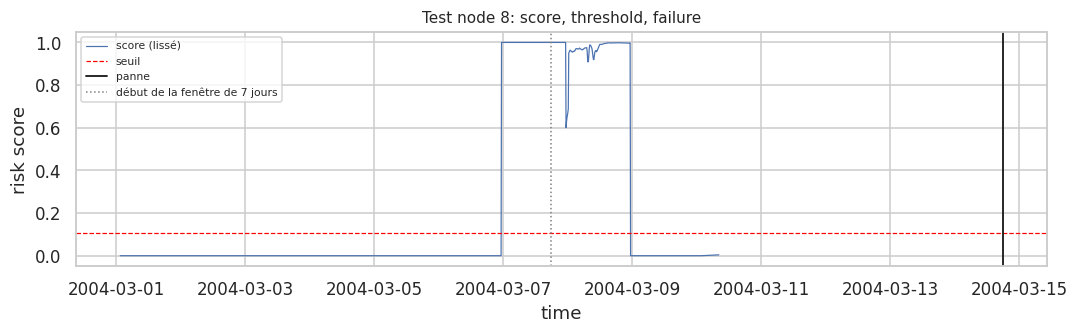

In [12]:
# ---- Figure du rapport : score du nœud de test 8 ----
if RUN_TEST:
    m = 8
    ts_, sm_ = nsm_t[m]
    on = ONSET[m]
    fig, ax = plt.subplots(figsize=(10, 3.2))
    ax.plot(ts_, sm_, lw=0.8, label="score (lissé)")
    ax.axhline(THR, color="red", ls="--", lw=0.8, label="seuil")
    ax.axvline(on, color="k", lw=1.2, label="panne")
    ax.axvline(on - pd.Timedelta(hours=MAX_LEAD_H), color="gray", ls=":", lw=1, label="début de la fenêtre de 7 jours")
    ax.set_title(f"Test node {m}: score, threshold, failure", fontsize=10)
    ax.set_xlabel("time"); ax.set_ylabel("risk score"); ax.legend(fontsize=7)
    plt.tight_layout()
    plt.savefig(FIG_DIR / "fig_test_noeud8.png", bbox_inches="tight")
    plt.show()

In [13]:
# ---- blind tails: nodes whose last scored row is long before the failure ----
bt = strict_dev[NAME].merge(onsets[["fail_type"]], left_on="node", right_index=True)
print(f"Development nodes with a blind tail longer than {MIN_LEAD_H} h:", int((bt.blind_tail_h > MIN_LEAD_H).sum()), "of", len(bt))
display(bt[bt.blind_tail_h > MIN_LEAD_H][["node", "fail_type", "outcome", "blind_tail_h"]].sort_values("blind_tail_h", ascending=False).head(10))
if RUN_TEST:
    bt_t = res_test_s
    print(f"Test nodes with a blind tail longer than {MIN_LEAD_H} h:", int((bt_t.blind_tail_h > MIN_LEAD_H).sum()), "of", len(bt_t))
    display(bt_t[bt_t.blind_tail_h > MIN_LEAD_H][["node", "fail_type", "outcome", "blind_tail_h"]])

Development nodes with a blind tail longer than 6 h: 6 of 41


,node,fail_type,outcome,blind_tail_h
14,20,silent,missed,113.527
37,50,silent,missed,33.128
10,16,garbage,missed,21.207
11,17,garbage,detected,21.189
8,13,garbage,detected,10.697
9,14,garbage,detected,6.100


Test nodes with a blind tail longer than 6 h: 2 of 10


,node,fail_type,outcome,blind_tail_h
1,8,silent,missed,105.717
2,12,garbage,detected,8.093


In [14]:
# ---- post-hoc: model alert OR no scorable data for NODATA_H hours ----
nd_dev = eval_strict(nsm, THR, nodata_h=NODATA_H)
rows = {"development: strict": summarize(strict_dev[NAME]), f"development: strict + no-data alert ({NODATA_H} h)": summarize(nd_dev)}
results["development_strict_nodata"] = summarize(nd_dev)
if RUN_TEST:
    nd_test = eval_strict(nsm_t, THR, nodata_h=NODATA_H)
    rows["test: strict"] = summarize(res_test_s)
    rows[f"test: strict + no-data alert ({NODATA_H} h)  [post-hoc]"] = summarize(nd_test)
    results["test_strict_nodata_posthoc"] = summarize(nd_test)
    display(nd_test.merge(onsets[["fail_type"]], left_on="node", right_index=True)[["node", "fail_type", "outcome", "lead_h", "false_alarms", "blind_tail_h"]])
pd.DataFrame(rows).T

,node,fail_type,outcome,lead_h,false_alarms,blind_tail_h
0,4,garbage,detected,128.695,1,0.029
1,8,silent,detected,106.217,1,105.717
2,12,garbage,detected,100.427,7,8.093
3,23,garbage,detected,159.920,1,0.087
4,24,garbage,detected,152.762,1,0.095
5,33,garbage,detected,121.379,2,0.046
6,37,garbage,detected,157.613,2,0.113
7,38,garbage,detected,128.018,1,0.018
8,44,garbage,detected,155.581,4,0.081
9,52,garbage,detected,127.296,2,0.129


,detected_%,late_%,missed_%,median_lead_h,false_alarms_per_node_day
development: strict,92.683,0.000,7.317,65.573,0.019
development: strict + no-data alert (6 h),100.000,0.000,0.000,141.696,0.175
test: strict,90.000,0.000,10.000,72.747,0.015
test: strict + no-data alert (6 h) [post-hoc],100.000,0.000,0.000,128.357,0.162


# Part C - Explainability (development nodes)
Explanations show **which variables influenced the score**. They do not prove the physical cause (here the cause is known: the battery).

### C.1 Permutation importance
Shuffle one feature at a time and measure the PR-AUC drop. Development rows, label `ttf_h <= H`.

Base PR-AUC on this sample: 0.9965 (the model was trained on these nodes, so this is a description, not a test)


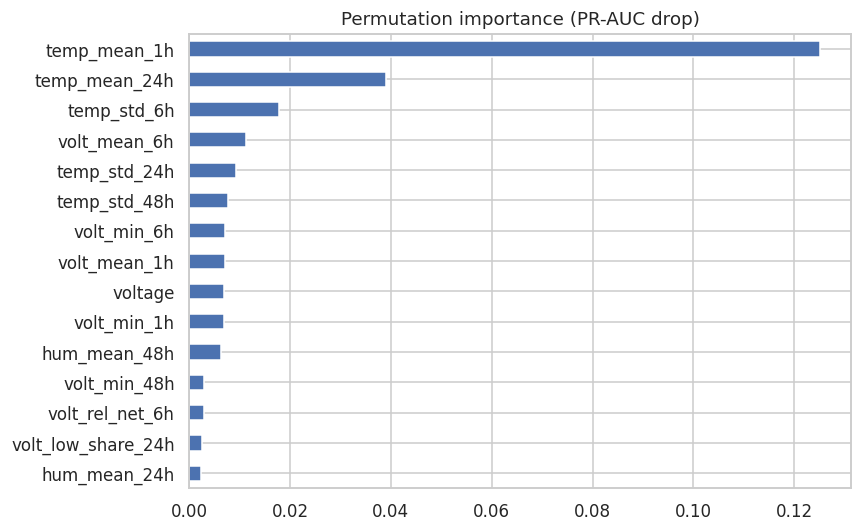

In [15]:
dev_rows = (pd.read_parquet(PROC_DIR / "features_intel.parquet", filters=[("moteid", "in", DEV_NODES)])
              .reset_index().sort_values(["moteid", "timestamp"]).reset_index(drop=True))
rng = np.random.default_rng(SEED)
y_all = (dev_rows.ttf_h <= H).astype(int).values
idx = np.sort(np.r_[np.where(y_all == 1)[0], rng.choice(np.where(y_all == 0)[0], min(8000, int((y_all == 0).sum())), replace=False)])
Xs, ys = dev_rows.loc[idx, FEATS].copy(), y_all[idx]

def score_fn(X):
    return model.predict_proba(X[FEATS])[:, 1]

base = average_precision_score(ys, score_fn(Xs))
imp = {}
for f in FEATS:
    drops = []
    for _ in range(3):
        Xp = Xs.copy(); Xp[f] = rng.permutation(Xp[f].values)
        drops.append(base - average_precision_score(ys, score_fn(Xp)))
    imp[f] = np.mean(drops)
imp = pd.Series(imp).sort_values(ascending=False)
imp.to_csv(RES_DIR / "intel_permutation_importance.csv")
print(f"Base PR-AUC on this sample: {base:.4f} (the model was trained on these nodes, so this is a description, not a test)")
imp.head(15).iloc[::-1].plot.barh(figsize=(8, 5), title="Permutation importance (PR-AUC drop)")
plt.tight_layout(); plt.savefig(FIG_DIR / "12_intel_permutation_importance.png", bbox_inches="tight"); plt.show()

### C.2 What a maintenance operator would see
One alert explained in plain language. For Logistic Regression the contribution of a feature is its coefficient times its standardised value.
For tree models we use SHAP. The score is **not a calibrated probability**.

In [16]:
TREE = ("RandomForest", "XGBoost", "DecisionTree")
if NAME in TREE:
    try:
        import shap
    except ImportError:
        %pip install -q shap
        import shap
    expl = shap.TreeExplainer(model)

def contributions(x):
    if NAME == "LogisticRegression":
        sc, lr = model.named_steps["standardscaler"], model.named_steps["logisticregression"]
        z = (x[FEATS].values - sc.mean_) / sc.scale_
        return pd.Series(z[0] * lr.coef_[0], index=FEATS)
    sv = expl.shap_values(x[FEATS])
    sv = sv[1] if isinstance(sv, list) else (sv[:, :, 1] if np.ndim(sv) == 3 else sv)
    return pd.Series(np.asarray(sv)[0], index=FEATS)

def explain_alert(row, top_n=5):
    x = row.to_frame().T.astype(float)
    s = float(score_fn(x)[0])
    print(f"Node {int(row.moteid)} | risk score {s:.3f} | status: {'ALERT' if s >= THR else 'NORMAL'} | hours to failure: {row.ttf_h:.1f}")
    top = contributions(x).sort_values(key=np.abs, ascending=False).head(top_n)
    print("Main contributing factors:")
    for f, v in top.items():
        print(f"  - {f} = {float(x[f].iloc[0]):.3f} ({'raises' if v > 0 else 'lowers'} the risk, {v:+.2f})")
    print("Recommended action:", "plan a battery replacement" if s >= THR else "no action")

pos = dev_rows[(dev_rows.ttf_h <= 24) & (dev_rows.ttf_h >= MIN_LEAD_H)]
r = pos.iloc[int(np.argmax(score_fn(pos)))]
explain_alert(dev_rows.loc[r.name, ["moteid", "ttf_h"] + FEATS])

Node 47 | risk score 1.000 | status: ALERT | hours to failure: 6.1
Main contributing factors:
  - temp_mean_1h = 40.793 (raises the risk, +17.67)
  - temp_mean_24h = 27.830 (raises the risk, +11.06)
  - temp_std_24h = 6.707 (lowers the risk, -5.50)
  - temp_std_48h = 6.329 (raises the risk, +5.01)
  - volt_mean_6h = 2.284 (raises the risk, +3.48)
Recommended action: plan a battery replacement


## 1. Save the final numbers

In [17]:
json.dump(results, open(RES_DIR / "intel_final_results.json", "w"), indent=2, default=str)
print(json.dumps(results, indent=2, default=str))

{
  "model": "LogisticRegression",
  "horizon_h": 24,
  "smooth_bins": 1,
  "threshold": 0.10787873676815204,
  "fa_budget": 0.02,
  "development": {
    "detected_%": 92.6829268292683,
    "late_%": 0.0,
    "missed_%": 7.317073170731707,
    "median_lead_h": 65.5728855223611,
    "false_alarms_per_node_day": 0.01947773369584814,
    "n_nodes": 41
  },
  "test": {
    "detected_%": 100.0,
    "late_%": 0.0,
    "missed_%": 0.0,
    "median_lead_h": 100.38285353402777,
    "false_alarms_per_node_day": 0.01469429306962115,
    "n_nodes": 10,
    "pr_auc": 0.6862277613532842,
    "roc_auc": 0.9867595516013425,
    "base_rate": 0.05983376727418386
  },
  "test_rule": {
    "detected_%": 90.0,
    "late_%": 0.0,
    "missed_%": 10.0,
    "median_lead_h": 72.11289581777778,
    "false_alarms_per_node_day": 0.0
  },
  "development_strict": {
    "detected_%": 92.6829268292683,
    "late_%": 0.0,
    "missed_%": 7.317073170731707,
    "median_lead_h": 65.5728855223611,
    "false_alarms_per_n